# Fechamentos e hiperbolicidade

O mapa de hiperbolicidade do modelo a dois fluidos, as regras de fração baixa e alta, a pressão interfacial de Bestion, a massa virtual, o atrito interfacial do estratificado e o fechamento de bolhas da tese contra o arrasto físico.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [015](../../docs/issues/015-fechamento-de-bolhas.md)
- [016](../../docs/issues/016-fracao-alta-anular.md)
- [017](../../docs/issues/017-fracao-baixa-bolhas-bestion.md)
- [018](../../docs/issues/018-massa-virtual.md)
- [019](../../docs/issues/019-atrito-interfacial-estratificado.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Hiperbolicidade dos fechamentos e regularização

O modelo a dois fluidos a 4 equações só é hiperbólico graças às correções de
pressão dos fechamentos (hidrostática do estratificado, 0.25·ρL·slip² das
bolhas). Onde essas correções falham, as velocidades características ficam
complexas, o problema de valor inicial é mal posto e a solução numérica
desenvolve oscilações na escala da malha, que pioram com o refinamento (foi o que
aconteceu na malha fina graduada: *chattering* da vazão de líquido no joelho com
período < 0.1 s e passos de 1 ms).

O mapa abaixo mostra max|Im λ| (m/s) em função da fração de gás e do
escorregamento para os fechamentos usados no caso:

* **estratificado** (linha): mal posto para αG ≲ 0.003 **mesmo sem
  escorregamento** — é o limite de camada de gás muito fina (hL → D), e é
  exatamente onde toda célula cheia de líquido é avaliada (αG cortado em 1e−3);
* **bolhas** (riser): mal posto em baixa fração com escorregamento (caso clássico);
* **tensão superficial** não resolve: é um termo dispersivo de 3ª ordem que não
  altera as características de 1ª ordem; limita o crescimento de ondas curtas, mas
  com σ = 0.05 N/m o corte capilar é milimétrico, irrelevante para células de metros;
* o que funciona: **padrão de bolhas abaixo de αG = 1 %** (`low_void_regime`,
  rampa C1; uma camada estratificada com 1 % da área não é física) **mais o termo de
  pressão interfacial** de Bestion/CATHARE, δ·αG·αL·ρG·ρL/(αG·ρL + αL·ρG)·(vG − vL)²
  com δ ≥ 1 (`interfacial_pressure`), que torna o modelo disperso hiperbólico para
  qualquer escorregamento. A combinação deixa o mapa inteiro com características reais.

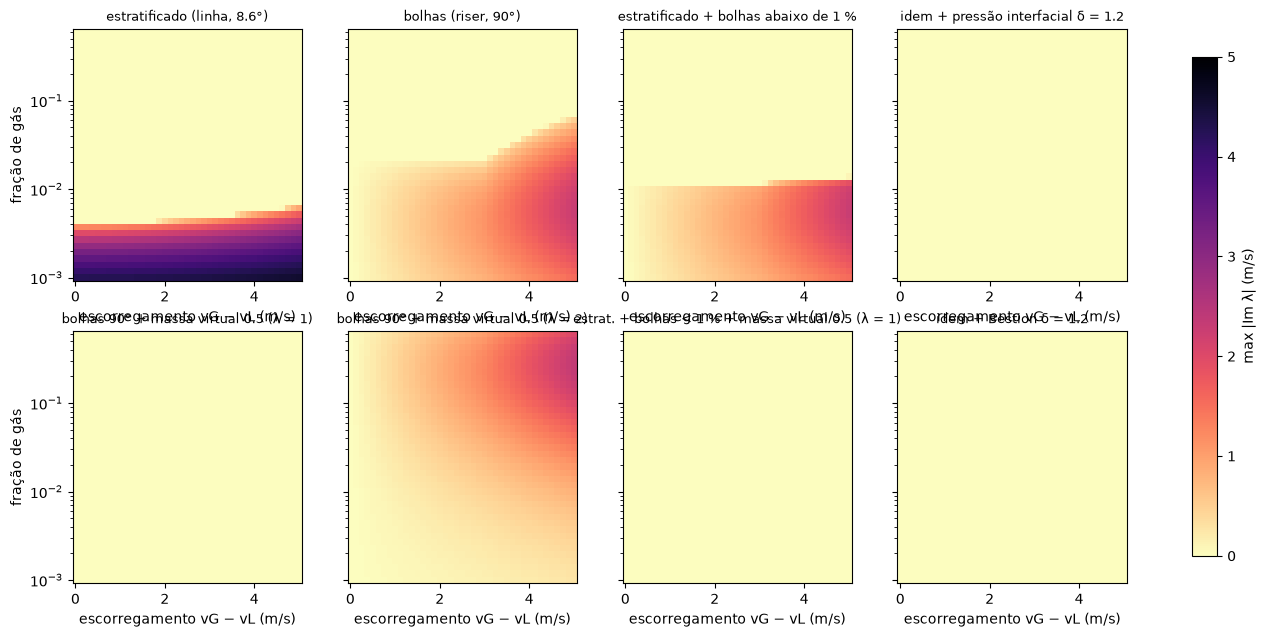

In [2]:
from mfsim.models.base import PipeParams
from mfsim.models.twofluid import TwoFluidModel

rhoL_, rhoG_, _, _ = fluid.props(6e5)
aG_grid = np.logspace(-3, np.log10(0.6), 40)
slip_grid = np.linspace(0.0, 5.0, 41)
variants = {
    "estratificado (linha, 8.6°)": dict(regime=4, theta=8.6),
    "bolhas (riser, 90°)": dict(regime=4, regime_vertical=2, theta=90.0),
    "estratificado + bolhas abaixo de 1 %": dict(regime=4, low_void_regime=2, theta=8.6),
    "idem + pressão interfacial δ = 1.2": dict(regime=4, low_void_regime=2, interfacial_pressure=1.2, theta=8.6),
    "bolhas 90° + massa virtual 0.5 (λ = 1)": dict(regime=4, regime_vertical=2, theta=90.0, virtual_mass=0.5),
    "bolhas 90° + massa virtual 0.5 (λ = 2)": dict(
        regime=4, regime_vertical=2, theta=90.0, virtual_mass=0.5, vm_lambda=2.0
    ),
    "estrat. + bolhas < 1 % + massa virtual 0.5 (λ = 1)": dict(
        regime=4, low_void_regime=2, theta=8.6, virtual_mass=0.5
    ),
    "idem + Bestion δ = 1.2": dict(regime=4, low_void_regime=2, theta=8.6, virtual_mass=0.5, interfacial_pressure=1.2),
}
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), sharey=True)
axes = axes.ravel()
for ax, (name, v) in zip(axes, variants.items()):
    v = dict(v)
    theta = v.pop("theta")
    m_ = TwoFluidModel(
        fluid, PipeParams(D=D, eps=1e-5, PR=1e6, vertical_angle=45.0, vertical_blend=20.0, low_void_alpha=0.01, **v)
    )
    Z = np.zeros((aG_grid.size, slip_grid.size))
    for i, aG_ in enumerate(aG_grid):
        vL_ = 0.5 / (rhoL_ * (1 - aG_) * A)
        y = np.array([[aG_, 0.6, 0.5, rhoG_ * aG_ * A * (vL_ + s_)] for s_ in slip_grid])
        Z[i] = np.abs(m_.eigenvalues(y, np.deg2rad(np.full(slip_grid.size, theta))).imag).max(axis=1)
    pc = ax.pcolormesh(slip_grid, aG_grid, Z, shading="nearest", vmin=0, vmax=5, cmap="magma_r")
    ax.set_yscale("log")
    ax.set_xlabel("escorregamento vG − vL (m/s)")
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("fração de gás")
axes[4].set_ylabel("fração de gás")
fig.colorbar(pc, ax=axes, label="max |Im λ| (m/s)", shrink=0.9)
plt.show()

**Massa virtual** (termo de Drew & Lahey, `virtual_mass` = C_vm pesado pelo indicador
de bolhas, `vm_lambda` = forma objetiva): a forma simples (λ = 2, só a diferença de
acelerações) piora a má-posição; a forma objetiva (λ = 1) com C_vm = 0.5 torna o
modelo hiperbólico em todo o mapa, tal como Bestion, mas com um termo físico. No
ciclo as duas regularizações se comportam de modo diferente (tabela abaixo): Bestion
não muda o ciclo e custa 1.6× mais passos; a massa virtual muda o intervalo entre
blowdowns em +7–10 % ao mesmo custo, e o faz igualmente nas formas λ = 1 e λ = 2, ou
seja, pelo acoplamento das inércias no riser em bolhas, não pela regularização. A
sensibilidade ao atrito interfacial do estratificado (`fi_mult` ×0.5/×2, Taitel–Dukler
contra Andritsos–Hanratty) é pequena: ±2 % no intervalo, ±8 % nos picos. Consequência
prática: a malha fina graduada no pescoço (30/10, razões 0.25/3), inviável com o alvo
de fração real (302.6k passos, 83 min, *chattering* nas células cheias de líquido),
custa 77.9k passos / 4 min com `noslip` e 68.9k / 3 min com massa virtual + bolhas
abaixo de 1 %; o alongamento do intervalo pela massa virtual mantém-se com o
refinamento (778 s contra 710 s).

**Contracorrente no riser.** Com bolhas prescritas no riser, o filme de líquido que
fica depois do blowdown (riser com mais de 90 % de gás em ~20 % do tempo) nunca
drena: o fechamento de bolhas a 95–100 % de gás exerce um arrasto de 3 a 4 ordens
de grandeza acima da gravidade e o líquido residual é expulso pelo topo (sobe a
mais de 0.5 m/s em 28 % do tempo, desce em 5 %). O fechamento anular dá um balanço
de forças sensato no filme, com inundação implícita perto de vG ≈ 10 m/s (Wallis
para D = 5 cm: ~8 m/s). A regra `high_void_regime=1` (anular acima de 90 % de gás,
rampa C1) deixa o filme drenar em 56–66 % desse tempo e alonga o intervalo entre
blowdowns em ~10 %; combinada com massa virtual e bolhas abaixo de 1 % é a corrida
mais barata (16.8k passos, 39 s) e passa a ser a configuração recomendada.

**Fechamento do riser: intermitente contra bolhas.** Nos estados do blowdown o
fechamento de bolhas exerce sobre o líquido um arrasto de −19 a −2400 N/m, o
intermitente (unidade de slug da tese) de −0.03 a −128 N/m: as bolhas carregam o
líquido pelo gás com muito mais eficiência (picos de 7–8 kg/s contra 4–6 com o IPE).
Mais importante: com `regime_vertical=3` **não há ciclo**; depois do primeiro
blowdown o sistema vai para golfadas contínuas pelo riser (αG 0.01–0.3, P_in ≈ 5.8
bar, produção 0.3–1.2 kg/s), com ou sem as regras físicas. Isto é coerente com o
critério de Bøe para o caso (vSL mínimo 1.03 m/s contra 0.30 de alimentação): o
ciclo obtido com bolhas prescritas é sustentado pelo fechamento, que retém o gás na
base do riser. A varredura em vSL acima do limiar de Bøe, com os dois fechamentos,
está na célula seguinte.

**Volume de gás a montante** (`upstream_volume`: vértice dinâmico de volume V com as
vazões de alimentação): o ciclo mantém-se com 0.1 a 2 m³ e o pico de líquido cresce
(6.1 → 9.3 kg/s), mas o vértice é um tanque de mistura cuja fração de gás cai a ≈ 0.05
(o líquido alimentado acumula), logo o volume de gás efetivo é ~5 % do nominal e a taxa
de pressurização da linha não muda. O gasoduto a montante representa-se prolongando a
linha horizontal de entrada (`L_h1` = 200 e 500 m, com o estratificado a guardar o gás
no topo): ver a tabela da fronteira. O vértice tipo separador fica pendente.

**Lei do gás** (γG politrópico): 1.3 (adiabático) encurta o intervalo entre blowdowns em
18 % no caso base e 9 % na linha longa e baixa os picos 10 %; 1.0 (isotérmico) alonga 4 %.
Gás mais rígido pressuriza o bolsão mais depressa; a amplitude de pressão não muda.

As duas tabelas abaixo são o diagnóstico do filme: o balanço de forças no filme (αG = 0.95, riser
vertical) segundo cada fechamento, e a fração do tempo em que o filme drena nas
corridas gravadas.

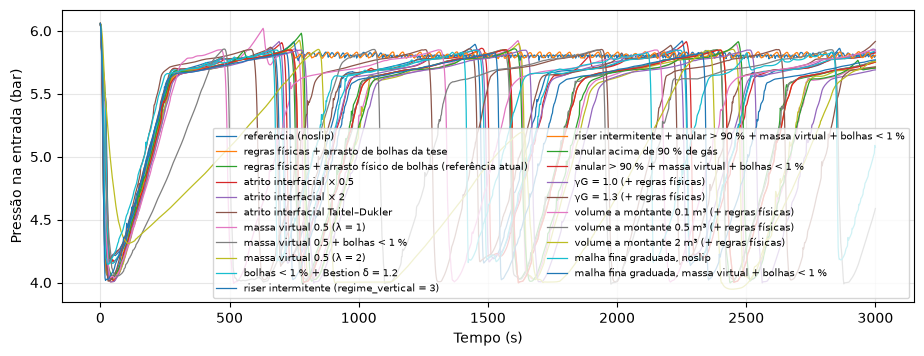

configuração                           passos    CPU blowdowns intervalo  pico máx   P_in (bar)
referência (noslip)                     25228    47 s         4     749 s    7.1 kg/s  4.14–5.92
regras físicas + arrasto de bolhas da tese    16833    97 s         4     800 s    6.1 kg/s  4.00–5.85
regras físicas + arrasto físico de bolhas (referência atual)    15602    89 s         4     799 s    6.5 kg/s  4.00–5.85
atrito interfacial × 0.5                30578    78 s         4     759 s    7.5 kg/s  4.17–5.91
atrito interfacial × 2                  20217    53 s         4     746 s    6.6 kg/s  4.15–5.92
atrito interfacial Taitel–Dukler        27250    71 s         4     735 s    6.5 kg/s  4.13–5.92
massa virtual 0.5 (λ = 1)               23597    50 s         4     826 s    7.6 kg/s  4.02–6.02
massa virtual 0.5 + bolhas < 1 %        21919    46 s         4     801 s    6.3 kg/s  4.03–5.85
massa virtual 0.5 (λ = 2)               20003    47 s         4     823 s    7.8 kg/s  4.02–5.93
b

In [3]:
runs_phys = {}
for tag, fname in (
    ("referência (noslip)", "severe_slug_blocked_conservative_arc_tol_noslip.npz"),
    ("regras físicas + arrasto de bolhas da tese", "severe_slug_blocked_conservative_arc_tol_hv_vm_lv_bd_tese.npz"),
    (
        "regras físicas + arrasto físico de bolhas (referência atual)",
        "severe_slug_blocked_conservative_arc_tol_hv_vm_lv_bd_phys.npz",
    ),
    ("atrito interfacial × 0.5", "severe_slug_blocked_conservative_arc_tol_fi05.npz"),
    ("atrito interfacial × 2", "severe_slug_blocked_conservative_arc_tol_fi20.npz"),
    ("atrito interfacial Taitel–Dukler", "severe_slug_blocked_conservative_arc_tol_fitaitel.npz"),
    ("massa virtual 0.5 (λ = 1)", "severe_slug_blocked_conservative_arc_tol_vm05.npz"),
    ("massa virtual 0.5 + bolhas < 1 %", "severe_slug_blocked_conservative_arc_tol_vm05_lv.npz"),
    ("massa virtual 0.5 (λ = 2)", "severe_slug_blocked_conservative_arc_tol_vm05_lam2.npz"),
    ("bolhas < 1 % + Bestion δ = 1.2", "severe_slug_blocked_conservative_arc_tol_bestion.npz"),
    ("riser intermitente (regime_vertical = 3)", "severe_slug_blocked_conservative_arc_tol_int.npz"),
    (
        "riser intermitente + anular > 90 % + massa virtual + bolhas < 1 %",
        "severe_slug_blocked_conservative_arc_tol_int_hv_vm_lv.npz",
    ),
    ("anular acima de 90 % de gás", "severe_slug_blocked_conservative_arc_tol_hv.npz"),
    ("anular > 90 % + massa virtual + bolhas < 1 %", "severe_slug_blocked_conservative_arc_tol_hv_vm_lv.npz"),
    ("γG = 1.0 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG10.npz"),
    ("γG = 1.3 (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_gammaG13.npz"),
    ("volume a montante 0.1 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup01.npz"),
    ("volume a montante 0.5 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup05.npz"),
    ("volume a montante 2 m³ (+ regras físicas)", "severe_slug_blocked_conservative_arc_tol_vup20.npz"),
    ("malha fina graduada, noslip", "severe_slug_blocked_conservative_arc_fine_graded_noslip.npz"),
    ("malha fina graduada, massa virtual + bolhas < 1 %", "severe_slug_blocked_conservative_arc_fine_graded_vm.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_phys[tag] = load_blocked_run(f)
if runs_phys:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for tag, r in runs_phys.items():
        ax.plot(r["T"], r["p"]["out"]["P_bar"][1], lw=0.9, label=tag)
    ax.set_ylabel("Pressão na entrada (bar)")
    ax.set_xlabel("Tempo (s)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=2)
    plt.show()
    print(
        f"{'configuração':36s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s}"
    )
    for tag, r in runs_phys.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:36s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f}"
        )

In [4]:
from mfsim.closures import ClosureInputs, annular, bubble
from mfsim.geometry import stratified_level

rhoL_f, rhoG_f = 900.0, 6.5
print(
    "Força líquida por metro sobre o filme (N/m; negativo = para baixo), αG = 0.95, riser vertical, peso do filme 0.87 N/m"
)
print(
    f"{'vL (m/s)':>9s} {'vG (m/s)':>9s} {'anular: GammaL':>15s} {'resultante':>11s} {'bolhas: GammaL':>15s} {'resultante':>11s}"
)
for vL_ in (-0.3, -0.1, 0.0):
    for vG_ in (1.0, 3.0, 6.0, 10.0):
        aG_ = np.array([0.95])
        hD_, beta_ = stratified_level(aG_)
        inp_ = ClosureInputs(
            alphaG=aG_,
            alphaL=1 - aG_,
            vL=np.array([vL_]),
            vLS=np.array([vL_ * (1 - aG_[0])]),
            vG=np.array([vG_]),
            vGS=np.array([vG_ * aG_[0]]),
            AreaL=A * (1 - aG_),
            AreaG=A * aG_,
            D=np.array([D]),
            eps=np.array([1e-5]),
            theta=np.array([np.pi / 2]),
            rhoL=np.array([rhoL_f]),
            rhoG=np.array([rhoG_f]),
            muL=np.array([2e-3]),
            muG=np.array([1.8e-5]),
            CL=np.array([9e-6]),
            CG=np.array([1.2e-5]),
            sigma=np.array([0.05]),
            beta=beta_,
            hD=hD_,
        )
        Sa_, Sb_ = annular(inp_), bubble(inp_)
        grav_ = -rhoL_f * (1 - aG_[0]) * A * 9.81
        print(
            f"{vL_:+9.1f} {vG_:9.1f} {Sa_.GammaL[0]:+15.3f} {grav_ - Sa_.GammaL[0]:+11.3f} {Sb_.GammaL[0]:+15.1f} {grav_ - Sb_.GammaL[0]:+11.1f}"
        )


def film_stats(r):
    """Fração do tempo com riser > 90 % de gás e, nessas células, filme descendo / líquido subindo > 0.5 m/s."""
    th_ = np.rad2deg(r["model"].pipes[0].scheme.theta_nodes)
    riser_ = np.flatnonzero(th_ > 80)
    aG_ = r["p"]["out"]["alphaG"][riser_]
    vL_ = r["p"]["out"]["velocidadeL"][riser_]
    vG_ = r["p"]["out"]["velocidadeG"][riser_]
    gf = aG_ > 0.9
    return (
        gf.mean(),
        (gf & (vL_ < -0.02) & (vG_ > 0.02)).sum() / max(1, gf.sum()),
        (gf & (vL_ > 0.5)).sum() / max(1, gf.sum()),
    )


print()
print(f"{'configuração':44s} {'riser > 90 % gás':>16s} {'filme descendo':>15s} {'líquido subindo > 0.5 m/s':>26s}")
for tag, r in runs_phys.items():
    if "malha fina" in tag:
        continue
    gf, down, up = film_stats(r)
    print(f"{tag:44s} {gf:16.1%} {down:15.1%} {up:26.1%}")

Força líquida por metro sobre o filme (N/m; negativo = para baixo), αG = 0.95, riser vertical, peso do filme 0.87 N/m
 vL (m/s)  vG (m/s)  anular: GammaL  resultante  bolhas: GammaL  resultante
     -0.3       1.0          -0.458      -0.409          -318.9      +318.1
     -0.3       3.0          -0.481      -0.385         -2055.1     +2054.2
     -0.3       6.0          -0.551      -0.316         -7490.0     +7489.1
     -0.3      10.0          -0.966      +0.099        -20020.5    +20019.6
     -0.1       1.0          -0.155      -0.712          -228.3      +227.5
     -0.1       3.0          -0.176      -0.690         -1813.5     +1812.6
     -0.1       6.0          -0.243      -0.623         -7022.0     +7021.1
     -0.1      10.0          -0.645      -0.222        -19250.5    +19249.7
     +0.0       1.0          -0.003      -0.863          -188.7      +187.8
     +0.0       3.0          -0.024      -0.843         -1698.4     +1697.5
     +0.0       6.0          -0.090      -0.77